# 02 - Exploratory Data Analysis (EDA)

**Goal:** understand the cleaned data with charts and numbers *before* modelling: what the target looks like, which features move with it, and whether features overlap with each other.

Input: `data/processed/fish_clean.csv` and `data/processed/bodyfat_clean.csv` (created in notebook 01).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 90

fish = pd.read_csv("data/processed/fish_clean.csv")
bf = pd.read_csv("data/processed/bodyfat_clean.csv")
print("Fish:", fish.shape, "| Body fat:", bf.shape)

def vif_table(df):
    """Variance Inflation Factor: how well each feature can be predicted from the other features.
    Rule of thumb: above 10 means strong overlap (multicollinearity)."""
    out = {}
    for c in df.columns:
        others = [x for x in df.columns if x != c]
        r2 = LinearRegression().fit(df[others], df[c]).score(df[others], df[c])
        out[c] = 1 / (1 - r2)
    return pd.Series(out, name="VIF").sort_values(ascending=False).round(1).to_frame()

Fish: (158, 7) | Body fat: (247, 14)


# Part A - Fish Market

### A1. How many fish of each species?

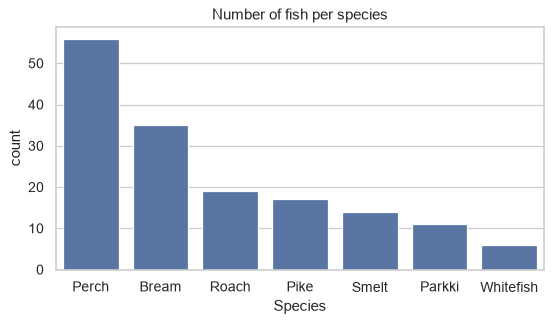

Species
Perch        56
Bream        35
Roach        19
Pike         17
Smelt        14
Parkki       11
Whitefish     6
Name: count, dtype: int64

In [2]:
fig, ax = plt.subplots(figsize=(7, 3.5))
order = fish["Species"].value_counts().index
sns.countplot(data=fish, x="Species", order=order, ax=ax)
ax.set_title("Number of fish per species")
plt.show()
fish["Species"].value_counts()

Perch is the biggest group (56 fish) and Whitefish the smallest (6). With so few Whitefish, predictions for that species will be less reliable.

### A2. The target: `Weight`

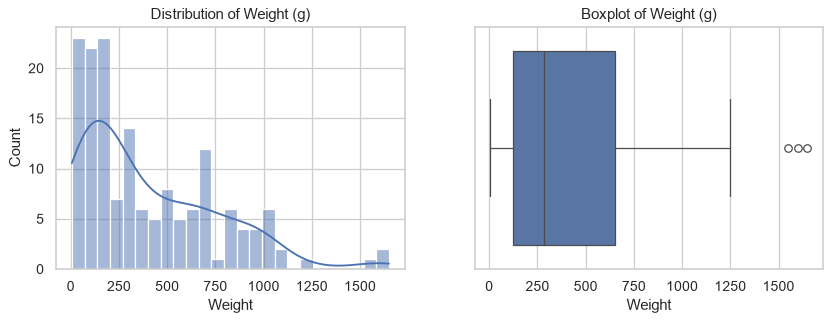

Skewness: 1.1 | mean: 400.8 | median: 281.5


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(fish["Weight"], bins=25, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Weight (g)")
sns.boxplot(x=fish["Weight"], ax=axes[1])
axes[1].set_title("Boxplot of Weight (g)")
plt.show()
print("Skewness:", round(fish["Weight"].skew(), 2), "| mean:", round(fish["Weight"].mean(), 1), "| median:", fish["Weight"].median())

Weight is **right-skewed** (mean 401 g is well above the median 282 g): most fish are small and a few are heavy.

### A3. Weight by species

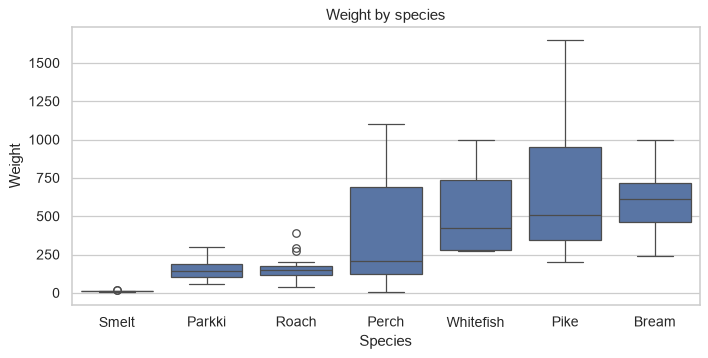

,count,mean,median,min,max
Species,,,,,
Bream,35,618.0,610.0,242.0,1000.0
Parkki,11,155.0,145.0,55.0,300.0
Perch,56,382.0,208.0,6.0,1100.0
Pike,17,719.0,510.0,200.0,1650.0
Roach,19,160.0,150.0,40.0,390.0
Smelt,14,11.0,10.0,7.0,20.0
Whitefish,6,531.0,423.0,270.0,1000.0


In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=fish, x="Species", y="Weight", order=fish.groupby("Species")["Weight"].median().sort_values().index, ax=ax)
ax.set_title("Weight by species")
plt.show()
fish.groupby("Species")["Weight"].agg(["count", "mean", "median", "min", "max"]).round(0)

Species matters a lot: a typical Smelt weighs about 10 g while a typical Pike weighs about 500 g. So `Species` should be included as an input.

### A4. Numeric features

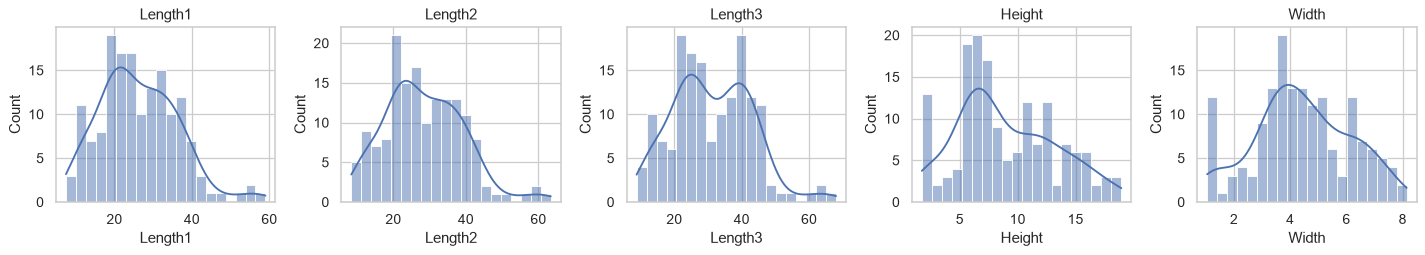

In [5]:
num_cols = ["Length1", "Length2", "Length3", "Height", "Width"]
fig, axes = plt.subplots(1, 5, figsize=(16, 3))
for ax, c in zip(axes, num_cols):
    sns.histplot(fish[c], bins=20, kde=True, ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

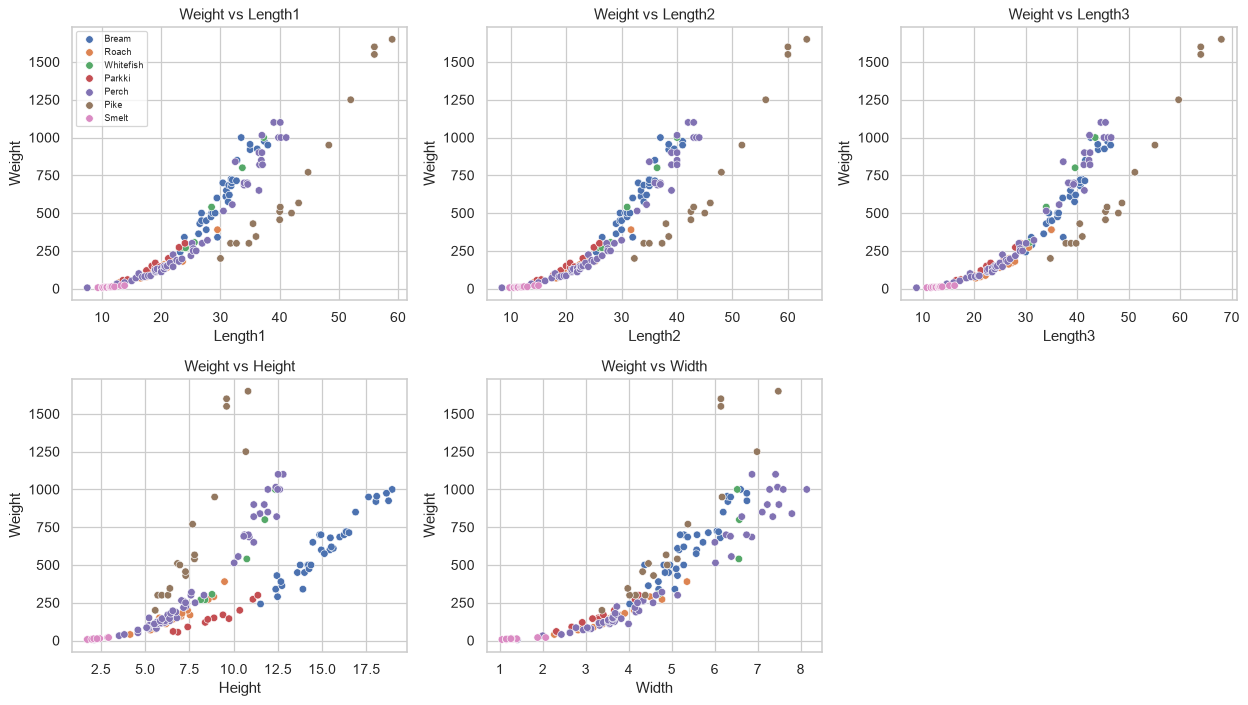

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.scatterplot(data=fish, x=c, y="Weight", hue="Species", ax=ax, legend=(c == "Length1"))
    ax.set_title(f"Weight vs {c}")
axes.ravel()[-1].axis("off")
axes[0, 0].legend(fontsize=7, loc="upper left")
plt.tight_layout()
plt.show()

Weight rises with every size measurement, but the curve bends upward (bigger fish gain weight faster). That is expected: weight grows roughly with volume, not length. A straight line will fit well in the middle but be less accurate at the extremes. Also notice that Pike (brown) sit below the other species: they are long but slim, so for the same length they weigh less. This is another reason to give the model the `Species`.

### A5. Correlation and overlap between features

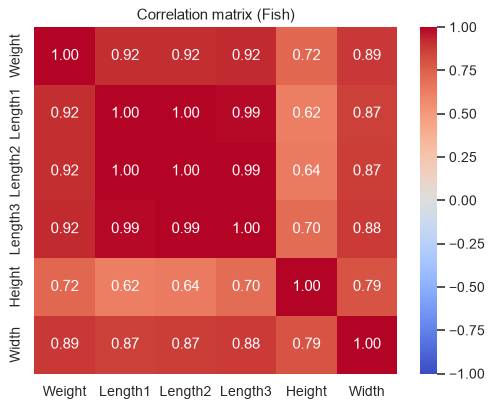

,corr with Weight
Length3,0.923
Length2,0.919
Length1,0.916
Width,0.887
Height,0.724


In [7]:
corr = fish[["Weight"] + num_cols].corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation matrix (Fish)")
plt.show()
corr["Weight"].drop("Weight").sort_values(ascending=False).round(3).to_frame("corr with Weight")

In [8]:
vif_table(fish[num_cols])

,VIF
Length2,2082.4
Length1,1677.7
Length3,421.8
Height,14.6
Width,12.3


`Length1`, `Length2` and `Length3` are almost copies of each other (VIF in the hundreds, far above 10). This is **multicollinearity**.
It does not hurt prediction accuracy much, but it makes the individual coefficients unstable, so we should not over-interpret them.

### Fish - key findings

1. 158 fish, 7 species; Perch (56) is the largest group and Whitefish (6) the smallest.
2. `Weight` is right-skewed; species strongly changes typical weight, so `Species` is a needed feature.
3. Every size measurement correlates strongly with weight (0.72 to 0.92); `Length3` is highest (0.92) and `Height` lowest (0.72).
4. The three length columns are nearly the same information (multicollinearity).
5. The weight-size relationship is slightly curved, so expect a linear model to be good but not perfect (especially for very small fish).

# Part B - Body Fat

### B1. The target: `BodyFat`

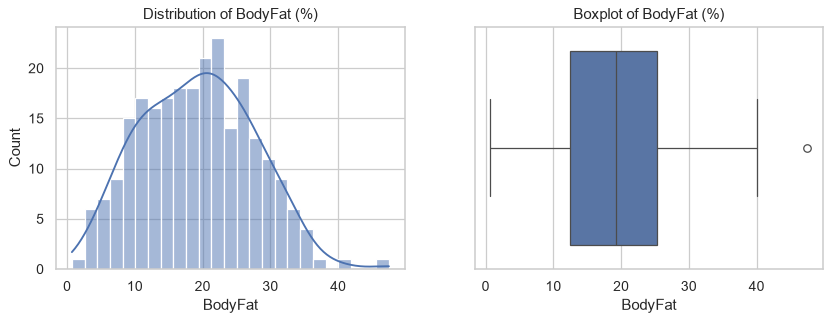

count    247.00
mean      19.24
std        8.27
min        0.70
25%       12.50
50%       19.30
75%       25.30
max       47.50
Name: BodyFat, dtype: float64
Skewness: 0.17


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(bf["BodyFat"], bins=25, kde=True, ax=axes[0])
axes[0].set_title("Distribution of BodyFat (%)")
sns.boxplot(x=bf["BodyFat"], ax=axes[1])
axes[1].set_title("Boxplot of BodyFat (%)")
plt.show()
print(bf["BodyFat"].describe().round(2))
print("Skewness:", round(bf["BodyFat"].skew(), 2))

Body fat is close to a bell shape (skewness 0.17), averaging about 19%. That is good news for linear regression.

### B2. Features

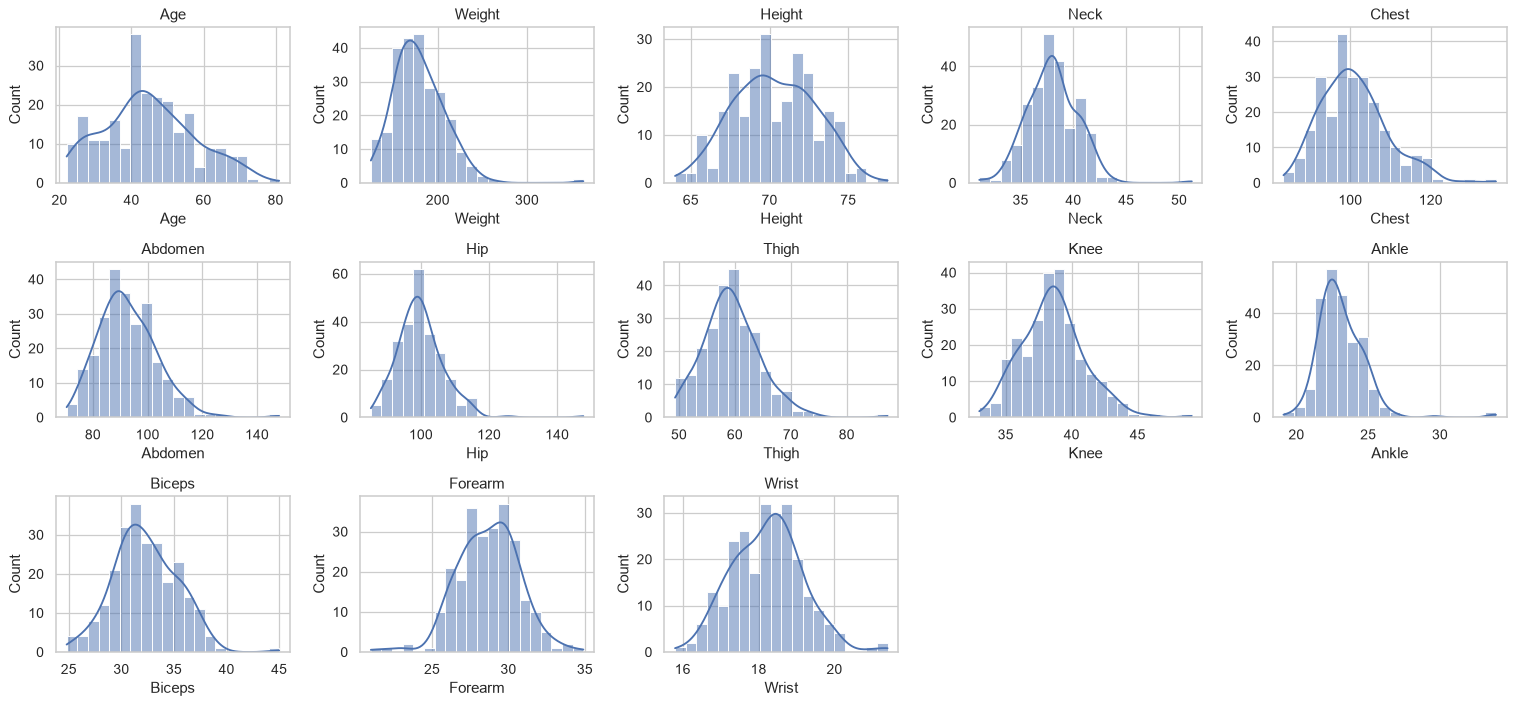

In [10]:
feats = [c for c in bf.columns if c != "BodyFat"]
fig, axes = plt.subplots(3, 5, figsize=(17, 8))
for ax, c in zip(axes.ravel(), feats):
    sns.histplot(bf[c], bins=20, kde=True, ax=ax)
    ax.set_title(c)
for ax in axes.ravel()[len(feats):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [11]:
# How many values are outliers by the 1.5 x IQR rule?
q1, q3 = bf[feats].quantile(0.25), bf[feats].quantile(0.75)
iqr = q3 - q1
outliers = ((bf[feats] < q1 - 1.5 * iqr) | (bf[feats] > q3 + 1.5 * iqr)).sum()
outliers.sort_values(ascending=False).to_frame("outlier count")

,outlier count
Forearm,5
Thigh,4
Wrist,4
Neck,3
Chest,3
Knee,3
Hip,3
Ankle,3
Abdomen,3
Weight,2


A handful of outliers exist in a few columns (very heavy or large men), but they are real measurements and not errors, so we keep them. One man (363 lb, 148 cm abdomen) is far from everyone else and pulls the trend lines in the plots below slightly, but we keep him too.

### B3. Which measurements relate to body fat?

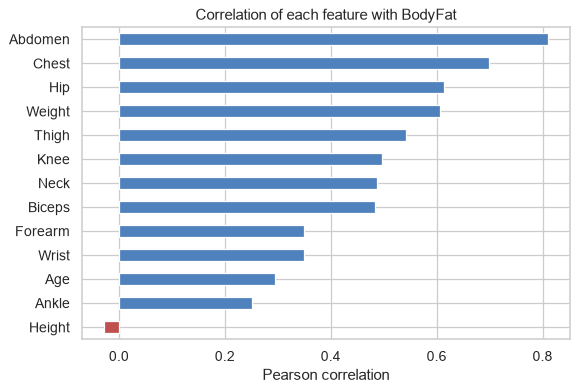

,corr with BodyFat
Abdomen,0.810
Chest,0.699
Hip,0.613
Weight,0.607
Thigh,0.541
Knee,0.498
Neck,0.488
Biceps,0.484
Forearm,0.350
Wrist,0.349


In [12]:
corr_t = bf.corr()["BodyFat"].drop("BodyFat").sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
corr_t.plot.barh(ax=ax, color=["#c0504d" if v < 0 else "#4f81bd" for v in corr_t])
ax.set_title("Correlation of each feature with BodyFat")
ax.set_xlabel("Pearson correlation")
plt.show()
corr_t.sort_values(ascending=False).round(3).to_frame("corr with BodyFat")

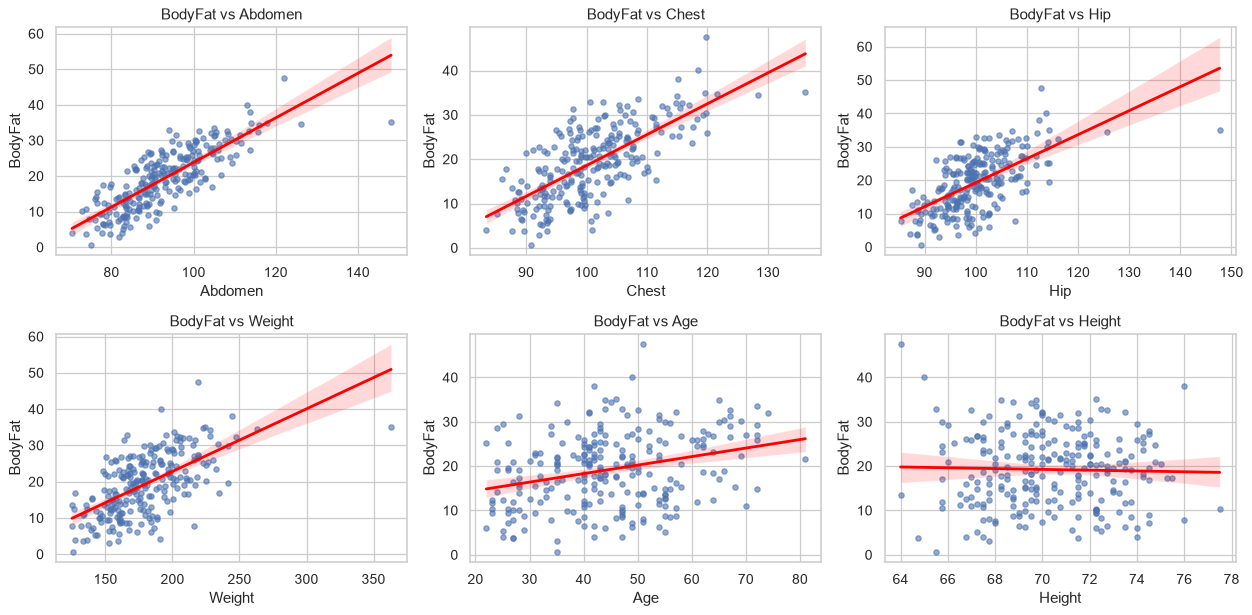

In [13]:
top = ["Abdomen", "Chest", "Hip", "Weight", "Age", "Height"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), top):
    sns.regplot(data=bf, x=c, y="BodyFat", ax=ax, scatter_kws={"s": 18, "alpha": .6}, line_kws={"color": "red"})
    ax.set_title(f"BodyFat vs {c}")
plt.tight_layout()
plt.show()

`Abdomen` (waist) is the strongest signal (0.81), followed by `Chest` (0.70), `Hip` and `Weight` (about 0.61). `Height` has essentially no relationship (-0.03). The relationships look reasonably straight, which suits a linear model.

### B4. Correlation between the features themselves

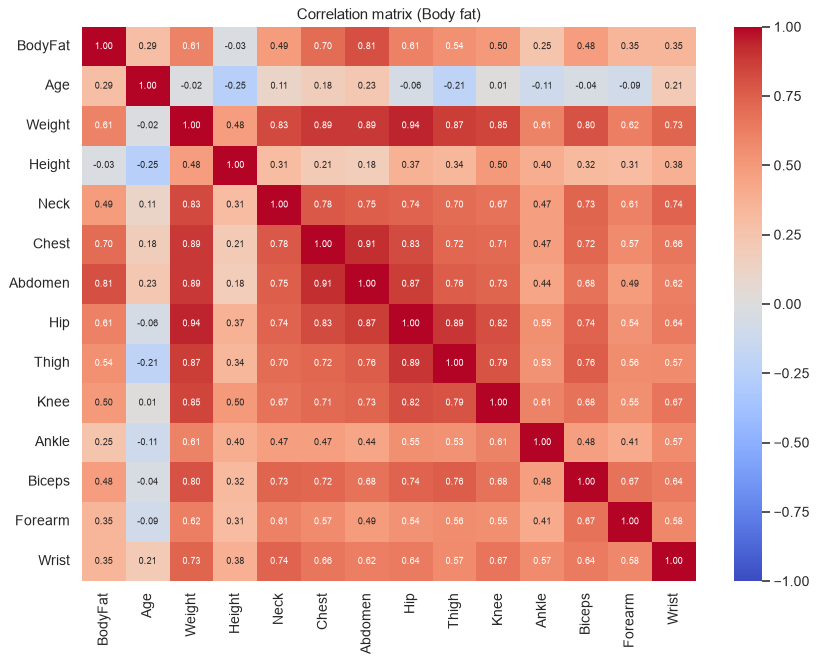

In [14]:
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(bf.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlation matrix (Body fat)")
plt.show()

In [15]:
vif_table(bf[feats])

,VIF
Weight,43.7
Hip,14.3
Abdomen,12.6
Chest,10.1
Thigh,7.7
Knee,4.7
Neck,4.3
Biceps,3.7
Wrist,3.3
Height,2.9


Body measurements overlap with each other (a heavier person has bigger chest, hips and thighs). `Weight` has the highest overlap (VIF about 44). Overlap is milder here than in the fish data, so predictions will be fine, but individual coefficients should be read with care.

### Body fat - key findings

1. 247 men; `BodyFat` is roughly bell-shaped with mean about 19%.
2. `Abdomen` (0.81), `Chest` (0.70), `Hip` (0.61) and `Weight` (0.61) are the strongest predictors; `Height` is almost useless on its own (-0.03).
3. Features overlap with each other (highest VIF: `Weight`, about 44), but not as extremely as the fish lengths.
4. Relationships look close to linear, so linear regression is a sensible first model.

## What we carry into modelling (notebook 03)

| Decision | Fish | Body fat |
|---|---|---|
| Target | `Weight` | `BodyFat` |
| Features | `Species` (one-hot encoded) + 5 size measurements | 13 body measurements |
| Scaling | standardise numeric columns | standardise numeric columns |
| Split | 80/20, stratified by species | 80/20 |
| Watch out for | curved relationship, near-duplicate length columns | overlapping measurements |